# EV Charging Demand — Time-Series Forecasting Analysis

## Project objective
The goal is to study how EV charging demand changes over time and to build forecasting models that estimate future **daily charging demand**.

## Beginner-friendly workflow
1. Prepare the date/time column.
2. Convert individual charging records into daily demand.
3. Study daily, weekly, and monthly patterns.
4. Check trend, seasonality, and noise.
5. Check whether the series is stationary.
6. Apply smoothing methods such as Moving Average and Exponential Smoothing.
7. Split the data by time into training and testing periods.
8. Compare forecasting models using MAE and RMSE.
9. Use differencing when needed for ARIMA.
10. Compare the forecasting approaches with a simple baseline before choosing the final model.

### Requirements covered
- Convert charging timestamps into a time-series structure.
- Aggregate demand at daily, weekly, and monthly levels.
- Study demand over time and identify trend.
- Analyze trend, weekly seasonality, and residual/noise.
- Check stationarity using the Augmented Dickey-Fuller (ADF) test.
- Apply Moving Average and Exponential Smoothing.
- Evaluate forecasts using **MAE** and **RMSE**.
- Apply first differencing when the original series is non-stationary.
- Fit and evaluate an ARIMA model.
- Compare the 7-day Moving Average, Exponential Smoothing, ARIMA, and a Naive Baseline.

### Main target used
`total_demand` = the sum of EV charging demand for each day.


## Step 1 — Load and prepare the timestamp

### What the code does
- Reads the cleaned EV charging dataset.
- Converts `start_full` into a real datetime column.
- `errors='coerce'` changes invalid date/time values to `NaT` instead of stopping the program.
- Sorts the records from earliest to latest.
- Checks for missing timestamps and prints the first and last dates.

### Concept
Time-series analysis depends on the correct chronological order. Before forecasting, the data must be arranged from past to future.

### Result
- Missing timestamps: **0**
- First timestamp: **30-Sep-2021 17:14:26**
- Last timestamp: **30-Sep-2022 23:11:59**

In [1]:
import pandas as pd

# Load dataset
df = pd.read_csv('data/ev_charging_featured_model.csv')

# Convert start_full to datetime
df['start_full'] = pd.to_datetime(df['start_full'],errors='coerce')

# Sort by time
df = df.sort_values('start_full').reset_index(drop=True)

# Check datetime
print("Missing start_full:", df['start_full'].isnull().sum())
print("Start date:", df['start_full'].min())
print("End date:", df['start_full'].max())

Missing start_full: 0
Start date: 2021-09-30 17:14:26
End date: 2022-09-30 23:11:59


### Dataset-column check

`df.columns` displays all available feature names.

For this time-series analysis, important columns include:
- `start_full` — when the charging session started.
- `demand` — charging demand for the session.
- `time_of_day` — Morning, Afternoon, Evening, or Night.

In [2]:
df.columns

Index(['chargercompany', 'location', 'chargertype', 'duration', 'demand',
       'start_full', 'start_hour', 'day_of_week_number', 'log_duration',
       'start_year', 'start_month', 'start_day', 'start_minute',
       'week_of_year', 'is_weekend', 'time_of_day', 'user_previous_sessions',
       'charger_previous_sessions', 'location_previous_sessions'],
      dtype='object')

## Step 2 — Create the main daily-demand time series

### What the code does
The original dataset contains multiple charging sessions on the same day. For time-series forecasting, these individual records are converted into **one value per day**.

The code:
1. Groups records by the date part of `start_full`.
2. Adds all `demand` values for that date.
3. Renames the result to `date` and `total_demand`.
4. Converts `date` back to datetime format.
5. Sorts the daily values chronologically.

### Result
The dataset contains **366 daily observations**.

In [3]:
daily_demand = (
    df.groupby(df['start_full'].dt.date)['demand']
      .sum()
      .reset_index()
)

# Rename columns
daily_demand.columns = ['date', 'total_demand']

# Convert date column to datetime
daily_demand['date'] = pd.to_datetime(
    daily_demand['date']
)

# Sort by date
daily_demand = (
    daily_demand
    .sort_values('date')
    .reset_index(drop=True)
)

print("\n--- Daily Demand ---")
print(daily_demand.head())

print("\nNumber of days:")
print(len(daily_demand))


--- Daily Demand ---
        date  total_demand
0 2021-09-30        579.19
1 2021-10-01       2434.41
2 2021-10-02       2087.74
3 2021-10-03       1907.85
4 2021-10-04       1768.66

Number of days:
366


## Step 3 — Plot daily demand over time

### How to read the graph
- **X-axis:** Date
- **Y-axis:** Total EV charging demand on that day
- Each point on the line represents one day's total demand.

### What the graph shows
Demand generally rises from roughly the lower 2,000 range in the early part of the dataset toward higher values later in the year. There are also strong day-to-day fluctuations, including occasional sharp peaks and drops.

The graph therefore suggests:
- an overall **upward trend**,
- substantial **daily variation**, and
- at least one unusually sharp decline near September 2022.

### Why this is useful
Before fitting a forecasting model, we first visually inspect whether the series contains trend, sudden changes, or repeating patterns.

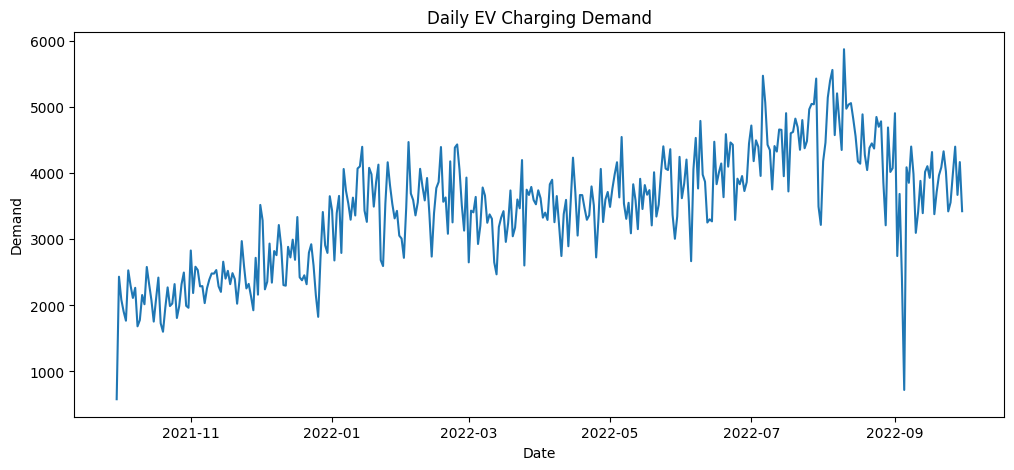

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(daily_demand['date'],
         daily_demand['total_demand'])

plt.title("Daily EV Charging Demand")
plt.xlabel("Date")
plt.ylabel("Demand")

plt.savefig(
    "images/time_series_daily_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7-day Moving Average — smoothing view

A 7-day moving average smooths the daily series using the mean of the most recent 7 daily values.

### What the code does
`rolling(window=7).mean()` calculates one-week rolling averages for the historical daily-demand series.

### Graph explanation
- **Actual** = original daily demand.
- **7-Day Moving Average** = smoother weekly average.
- Sudden daily spikes and drops are reduced because seven days are averaged together.

### Important: smoothing vs forecasting
This particular `MA_7` column is used for **smoothing/EDA**. It helps us see the underlying weekly movement in the historical series.

Later, in **Step 13**, a separate 7-day Moving Average **forecasting model** is created. That forecasting version:
1. uses the latest 7 available actual demand values,
2. predicts the next day's demand,
3. adds the newly observed actual value to history,
4. repeats the process across the test period,
5. evaluates the forecasts using MAE and RMSE.

**Simple difference:**
- `rolling(window=7).mean()` here → “What is the smoothed historical pattern?”
- Step 13 walk-forward Moving Average → “What is the next-day forecast, and how accurate is it?”


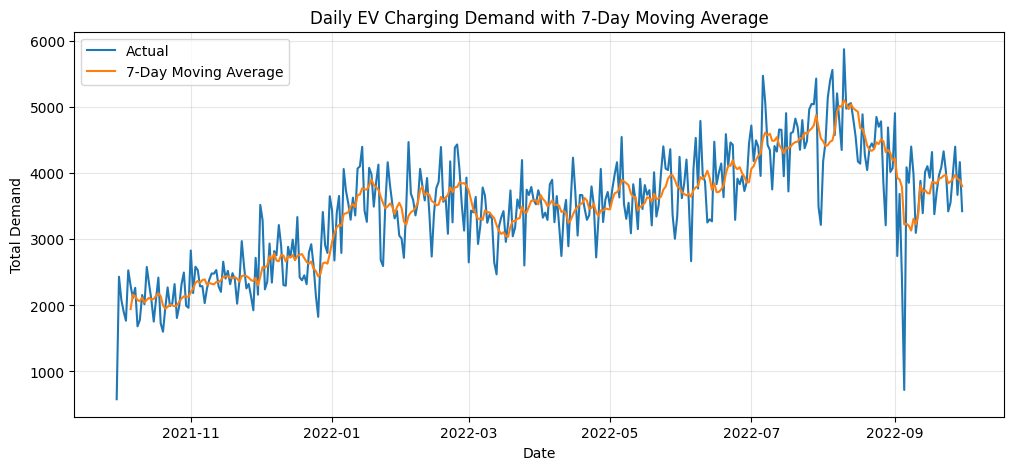

In [5]:
daily_demand['MA_7'] = (
    daily_demand['total_demand']
    .rolling(window=7)
    .mean()
)

plt.figure(figsize=(12,5))

plt.plot(
    daily_demand['date'],
    daily_demand['total_demand'],
    label='Actual'
)

plt.plot(
    daily_demand['date'],
    daily_demand['MA_7'],
    label='7-Day Moving Average'
)

plt.title('Daily EV Charging Demand with 7-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Total Demand')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Step 4 — EDA: Weekly demand aggregation

### What the code does
`resample('W-SUN')` groups daily demand into weekly buckets ending on Sunday and adds the demand inside each week.

### Why weekly demand is useful
Daily values can be noisy. Weekly aggregation reduces some of that day-to-day variation and makes medium-term movement easier to see.

### Graph explanation
The weekly series shows a broader upward movement through much of the year, followed by a decline toward the end of the observed period. Because each point represents a whole week, the graph looks smoother than the daily series.

### Important limitation
The first weekly bucket is incomplete because the dataset begins on **Thursday, 30-Sep-2021** rather than at the beginning of a full week.


In [6]:
weekly_demand = (
    daily_demand
    .resample('W-SUN', on='date')['total_demand']
    .sum()
    .reset_index()
)

print("\n--- Weekly Demand ---")
print(weekly_demand.head())


--- Weekly Demand ---
        date  total_demand
0 2021-10-03       7009.19
1 2021-10-10      14440.27
2 2021-10-17      15011.87
3 2021-10-24      14009.11
4 2021-10-31      14897.72


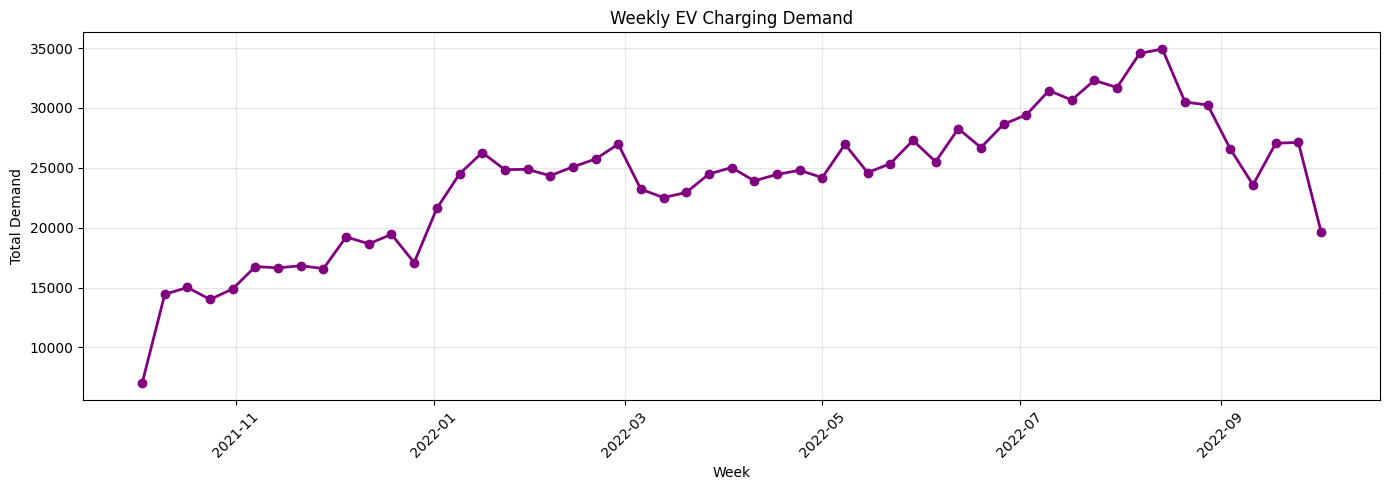

In [7]:
plt.figure(figsize=(14, 5))

plt.plot(
    weekly_demand['date'],
    weekly_demand['total_demand'],
    marker='o',
    color='purple',
    linewidth=2
)

plt.title("Weekly EV Charging Demand")
plt.xlabel("Week")
plt.ylabel("Total Demand")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Step 5 — EDA: Monthly demand aggregation

### What the code does
- `resample('ME')` adds daily demand within each calendar month.
- A readable label such as `Oct 2021` or `Jan 2022` is created for display.

### Observation
The first monthly value, **Sep 2021 = 579.19**, is not a full month. It contains only the final hours of 30-Sep-2021.

Complete-month examples:
- Oct 2021: **64,788.97**
- Jan 2022: **109,610.54**
- Jul 2022: **139,534.64**
- Aug 2022: **143,011.77**

### Graph explanation
From October 2021 to January 2022, monthly demand increases. Around February to April, demand is relatively stable. Demand then rises again and reaches its highest monthly level around August 2022 before decreasing in September.

The very small September 2021 bar should **not** be treated as a genuinely low-demand month because only a partial day is available.


In [8]:
monthly_demand = (
    daily_demand
    .resample('ME', on='date')['total_demand']
    .sum()
    .reset_index()
)

print("\n--- Monthly Demand ---")
print(monthly_demand.head())


--- Monthly Demand ---
        date  total_demand
0 2021-09-30        579.19
1 2021-10-31      64788.97
2 2021-11-30      71692.14
3 2021-12-31      85025.76
4 2022-01-31     109610.54


In [9]:
monthly_demand_display = monthly_demand.copy()

monthly_demand_display['month_name'] = (
    monthly_demand_display['date'].dt.strftime('%b %Y')
)

print(
    monthly_demand_display[
        ['month_name', 'total_demand']
    ]
)

   month_name  total_demand
0    Sep 2021        579.19
1    Oct 2021      64788.97
2    Nov 2021      71692.14
3    Dec 2021      85025.76
4    Jan 2022     109610.54
5    Feb 2022     103046.61
6    Mar 2022     103879.49
7    Apr 2022     104199.69
8    May 2022     115281.51
9    Jun 2022     117535.70
10   Jul 2022     139534.64
11   Aug 2022     143011.77
12   Sep 2022     111191.48


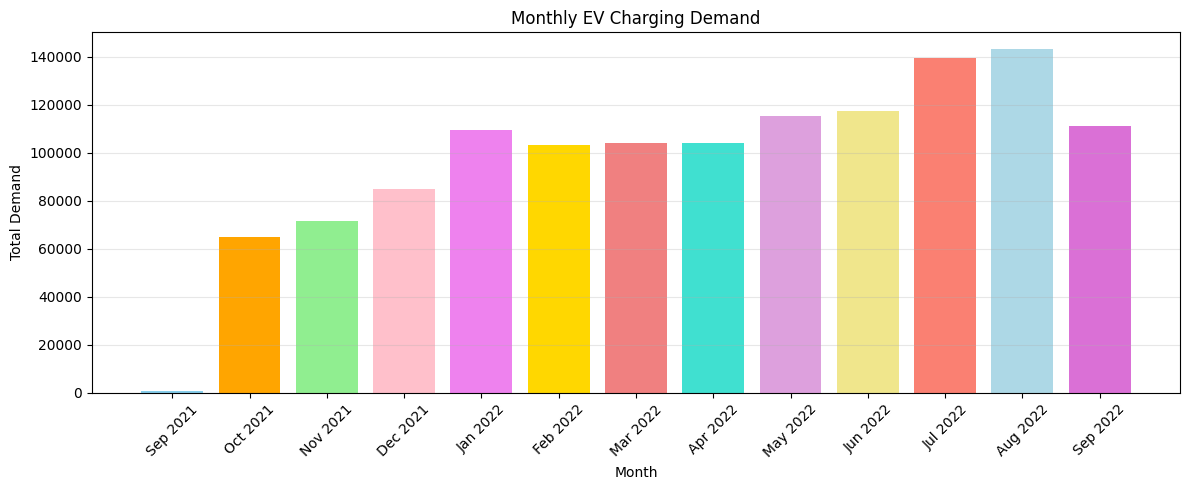

In [10]:
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_demand['date'].dt.strftime('%b %Y'),
    monthly_demand['total_demand'],
    color=[
        'skyblue', 'orange', 'lightgreen', 'pink',
        'violet', 'gold', 'lightcoral', 'turquoise',
        'plum', 'khaki', 'salmon', 'lightblue',
        'orchid'
    ][:len(monthly_demand)]
)

plt.title("Monthly EV Charging Demand")
plt.xlabel("Month")
plt.ylabel("Total Demand")

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 6 — Overall demand by time of day

### What the code does
The data is grouped by `time_of_day`, and all demand values inside each category are added.

### Result
- **Evening:** 439,600.16 — highest total demand
- Afternoon: 297,331.43
- Morning: 277,904.82
- **Night:** 254,541.08 — lowest total demand

### Graph explanation
The bar chart compares the total demand contributed by each time-of-day category across the entire dataset. 

This suggests that EV charging demand is more concentrated during evening hours, possibly because more users charge vehicles after daily travel activities.


--- Demand by Time of Day ---
  time_of_day     demand
1     Evening  439600.16
0   Afternoon  297331.43
2     Morning  277904.82
3       Night  254541.08

Highest demand time period:
time_of_day      Evening
demand         439600.16
Name: 1, dtype: object

Lowest demand time period:
time_of_day        Night
demand         254541.08
Name: 3, dtype: object


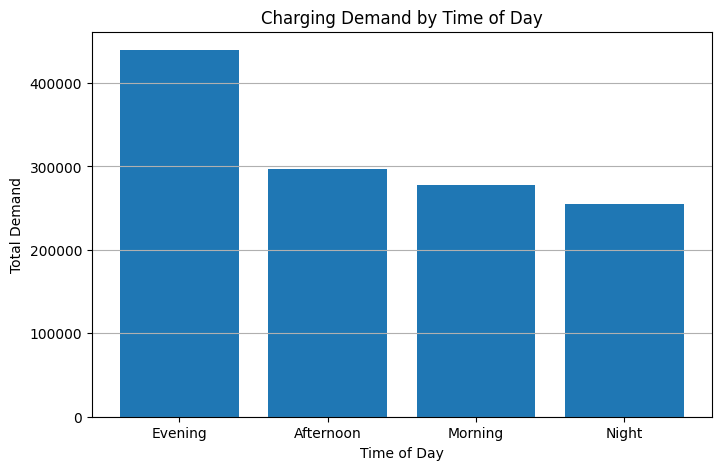

In [11]:
# Time of day demand
# During which time period is charging demand highest? - Morning / Afternoon / Evening / Night

time_demand = (
    df.groupby('time_of_day')['demand']
      .sum()
      .reset_index()
      .sort_values('demand', ascending=False)
)

print("\n--- Demand by Time of Day ---")
print(time_demand)


# Highest time period
highest_time = time_demand.iloc[0]

# Lowest time period
lowest_time = time_demand.iloc[-1]

print("\nHighest demand time period:")
print(highest_time)

print("\nLowest demand time period:")
print(lowest_time)


# Plot
plt.figure(figsize=(8, 5))

plt.bar(
    time_demand['time_of_day'],
    time_demand['demand']
)

plt.title('Charging Demand by Time of Day')
plt.xlabel('Time of Day')
plt.ylabel('Total Demand')

plt.grid(axis='y')

plt.show()

## Step 7 — Daily demand by `time_of_day`

The previous graph totals each time-of-day category across the whole dataset. This step instead creates separate **daily time series** for:
- Morning
- Afternoon
- Evening
- Night

### What the code does
1. Groups demand by both date and `time_of_day`.
2. Adds demand within each date/category combination.
3. Uses `pivot()` to convert the four categories into separate columns.
4. Uses `fillna(0)` when a category has no demand recorded on a day.

### Graph explanation
The four lines show how demand for each time period changes across the year. Evening is generally higher, but all four categories fluctuate over time.

This view is useful because it shows both **which period is usually higher** and **how that pattern changes through time**.


time_of_day  Afternoon  Evening  Morning   Night
date                                            
2021-09-30        0.00   198.43     0.00  380.76
2021-10-01      551.37   934.27   516.03  432.74
2021-10-02      537.76   780.65   351.87  417.46
2021-10-03      424.10   559.64   387.79  536.32
2021-10-04      419.62   496.65   416.39  436.00


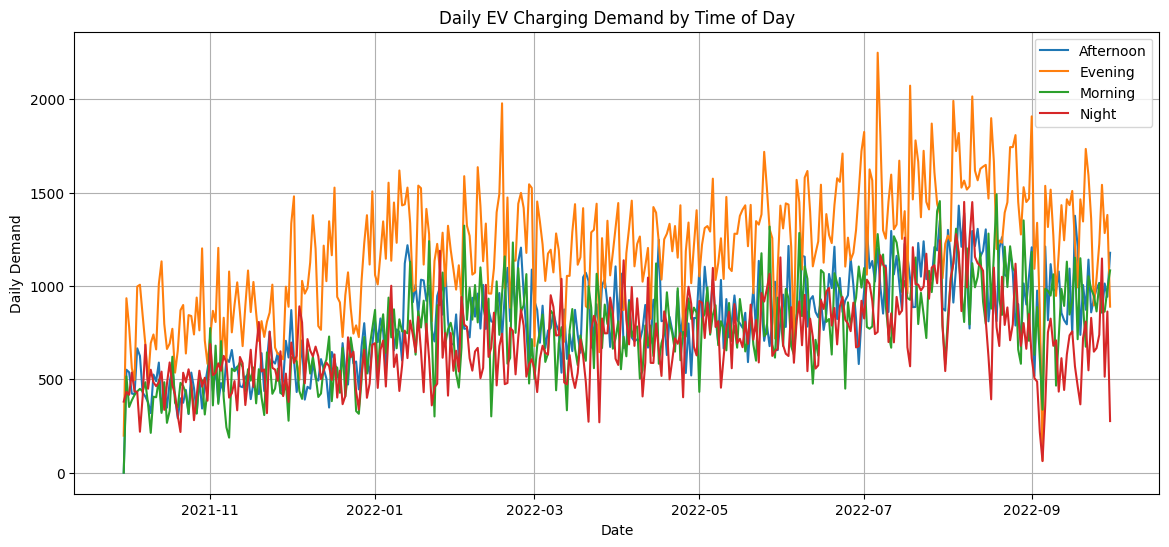

In [12]:
# Daily demand by time of day

daily_time_of_day = (
    df.groupby([
        df['start_full'].dt.date,
        'time_of_day'
    ])['demand']
      .sum()
      .reset_index()
)

daily_time_of_day.columns = [
    'date',
    'time_of_day',
    'total_demand'
]

daily_time_of_day['date'] = pd.to_datetime(
    daily_time_of_day['date']
)

time_of_day_daily_pivot = (
    daily_time_of_day
    .pivot(
        index='date',
        columns='time_of_day',
        values='total_demand'
    )
    .fillna(0)
)

print(time_of_day_daily_pivot.head())

plt.figure(figsize=(14, 6))

for period in time_of_day_daily_pivot.columns:
    plt.plot(
        time_of_day_daily_pivot.index,
        time_of_day_daily_pivot[period],
        label=period
    )

plt.title('Daily EV Charging Demand by Time of Day')
plt.xlabel('Date')
plt.ylabel('Daily Demand')
plt.legend()
plt.grid()
plt.show()

## 7-day average demand by `time_of_day`

### Why use a 7-day rolling average?
A 7-day window averages approximately one week of daily observations. This reduces short-term noise and makes the underlying movement in each time-of-day category easier to compare.

### What the graph shows
The Evening line is generally above the other periods, confirming that Evening demand tends to be higher. Morning, Afternoon, and Night are lower overall, although all categories rise and fall over time.

### Important point
A rolling average is a **smoothing technique**. It helps us understand the pattern.


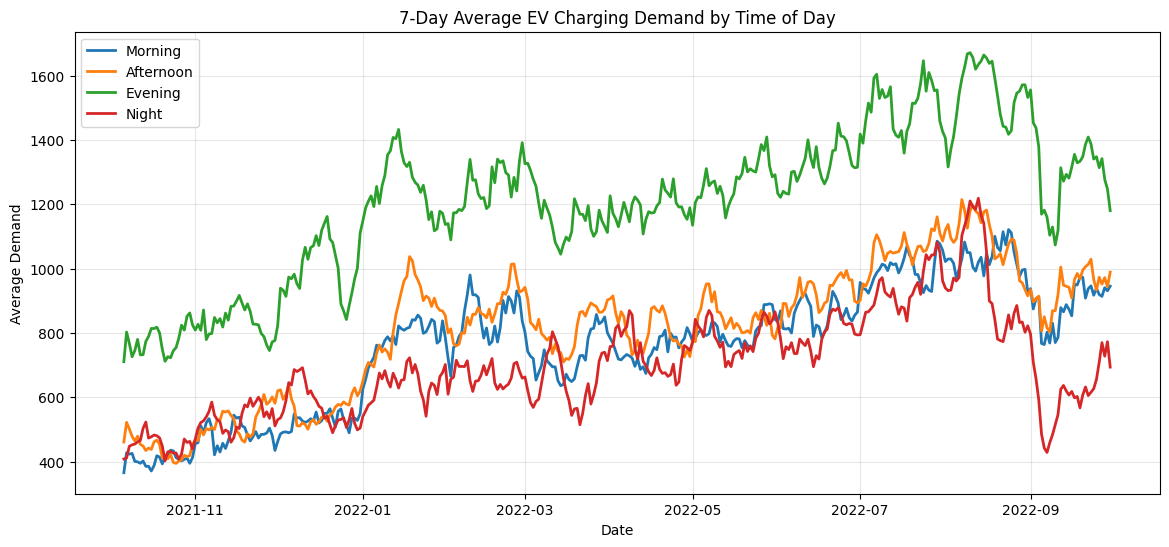

In [13]:
# 7-day Average demand for time_of_day

time_of_day_7day = (
    time_of_day_daily_pivot
    .rolling(window=7)
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    time_of_day_7day.index,
    time_of_day_7day['Morning'],
    label='Morning',
    linewidth=2
)

plt.plot(
    time_of_day_7day.index,
    time_of_day_7day['Afternoon'],
    label='Afternoon',
    linewidth=2
)

plt.plot(
    time_of_day_7day.index,
    time_of_day_7day['Evening'],
    label='Evening',
    linewidth=2
)

plt.plot(
    time_of_day_7day.index,
    time_of_day_7day['Night'],
    label='Night',
    linewidth=2
)

plt.title('7-Day Average EV Charging Demand by Time of Day')
plt.xlabel('Date')
plt.ylabel('Average Demand')

plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "images/time_of_day_7day.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 8 — Decomposition: Observed, Trend, Seasonality, and Noise

`seasonal_decompose(..., model='additive', period=7)` separates daily demand into components.

### Why `period=7`?
The series is daily, so 7 observations represent one week. This allows us to examine a repeating weekly pattern.

### Four plots
1. **Observed** — original daily charging demand.
2. **Trend** — the smoother long-term direction.
3. **Seasonal** — the repeating weekly effect.
4. **Residual/Noise** — what remains after trend and seasonality are removed.

For an additive decomposition:

**Observed ≈ Trend + Seasonal + Residual**

### Graph explanation
- The **Trend** component shows the broader increase and later decline.
- The **Seasonal** component shows a regular 7-day repeating pattern.
- The **Residual** component contains irregular changes that are not explained by the estimated trend or weekly seasonality.

### Why this matters
Decomposition helps us understand **what creates the movement** in the series before selecting a forecasting approach.


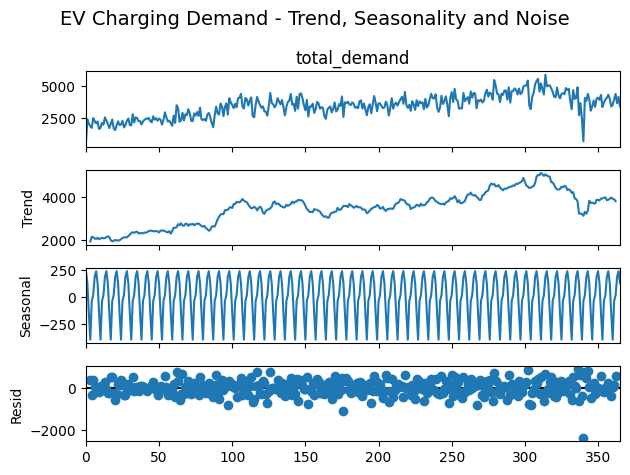

In [14]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    daily_demand['total_demand'],
    model='additive',
    period=7
)

# Plot all components together
decomposition.plot()

plt.suptitle(
    'EV Charging Demand - Trend, Seasonality and Noise',
    fontsize=14
)

plt.tight_layout()
plt.show()

## Step 9 — Stationarity check using the ADF test

### What is stationarity?
A stationary time series has statistical behavior that is relatively stable over time, especially its overall level/mean and variability.

Many classical time-series models work better when the series is stationary.

### What does the ADF test do?
The Augmented Dickey-Fuller (ADF) test helps us decide whether the series has a unit-root/non-stationary behavior.

### Simple decision rule used here
- **p-value ≤ 0.05** → evidence supports treating the series as stationary.
- **p-value > 0.05** → we do not have enough evidence to treat it as stationary.

### Result
- ADF statistic: **-1.8807**
- p-value: **0.3412**

The original daily-demand series is considered non-stationary because the p-value (0.3412) is greater than 0.05, indicating the presence of trend or changing behavior over time.

In [15]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(
    daily_demand['total_demand']
)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -1.8807158754027797
p-value: 0.34118663700162055


## Step 10 — Time-based train-test split

Time-series data has a natural order. The model must learn from the **past** and predict the **future**.

Therefore:
- **Earliest 80%** → training data
- **Latest 20%** → test data

### Saved result
- Train: **292 days**, 30-Sep-2021 to 18-Jul-2022
- Test: **74 days**, 19-Jul-2022 to 30-Sep-2022

### Why this is important
If future dates were mixed into training, the model would indirectly see information from the future. That would cause data leakage and give an unrealistic evaluation.

In [16]:
# 80% Train and 20% Test
split_idx = int(len(daily_demand) * 0.80)

train = daily_demand.iloc[:split_idx]
test = daily_demand.iloc[split_idx:]

print("Train size:", len(train))
print("Test size :", len(test))

Train size: 292
Test size : 74


In [17]:
print("\nTrain Period:")
print(train['date'].min(), "to", train['date'].max())

print("\nTest Period:")
print(test['date'].min(), "to", test['date'].max())


Train Period:
2021-09-30 00:00:00 to 2022-07-18 00:00:00

Test Period:
2022-07-19 00:00:00 to 2022-09-30 00:00:00


## Step 11 — Exponential Smoothing: additive trend only

### What is Exponential Smoothing?
Exponential Smoothing is a forecasting method that gives more importance to recent observations while estimating the underlying level and trend.

This first version uses:
- `trend='add'`
- no explicit seasonal component.

### What the code does
1. Fits the model using only the training data.
2. Learns an additive trend.
3. Forecasts the same number of days as the test period.

### Evaluation metrics
- **MAE = 784.00**
- **RMSE = 1028.75**

### MAE — Mean Absolute Error
MAE is the average absolute difference between actual demand and forecast demand.

**Simple meaning:**  
> “On average, how far is my forecast from the real value?”

Lower MAE is better.

### RMSE — Root Mean Squared Error
RMSE also measures forecast error, but it gives more weight to larger mistakes.

**Simple meaning:**  
> “How large are my errors when bigger mistakes are penalized more strongly?”

Lower RMSE is better.

### Graph explanation
The forecast line is smooth and continues the learned upward trend. Actual test demand is much more volatile and includes sharp drops. Because the model only learns a general additive trend, it cannot reproduce all daily changes.

### Interpretation
The model captures broad direction but its test error is relatively high compared with the better-performing models later in the notebook.


In [18]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model = ExponentialSmoothing(
    train['total_demand'],
    trend='add',
)

model_fit = model.fit()

forecast = model_fit.forecast(len(test))

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    test['total_demand'],
    forecast
)

rmse = np.sqrt(
    mean_squared_error(
        test['total_demand'],
        forecast
    )
)

print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE : 784.0
RMSE: 1028.75


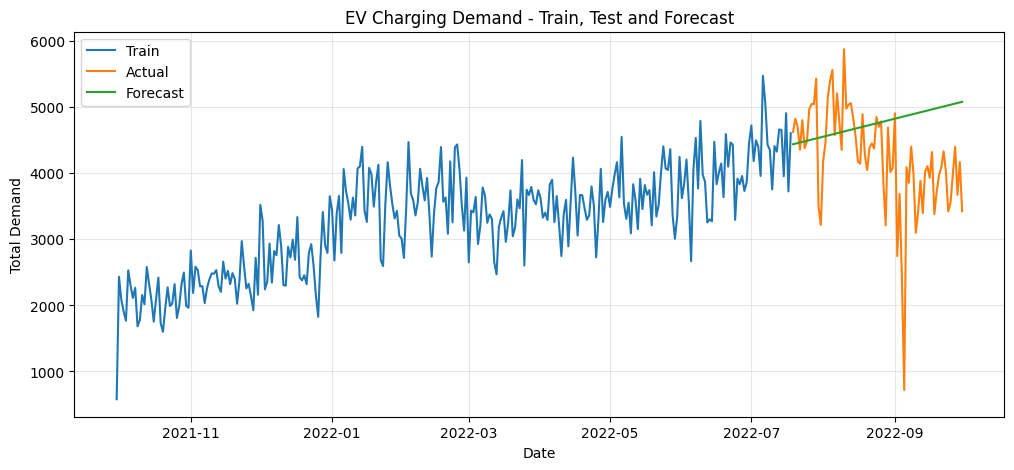

In [20]:
plt.figure(figsize=(12,5))

# Training data
plt.plot(
    train['date'],
    train['total_demand'],
    label='Train'
)

# Actual test data
plt.plot(
    test['date'],
    test['total_demand'],
    label='Actual'
)

# Forecast for test period
plt.plot(
    test['date'],
    forecast,
    label='Forecast'
)

plt.title('EV Charging Demand - Train, Test and Forecast')
plt.xlabel('Date')
plt.ylabel('Total Demand')

plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "images/es_trend_only.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 12 — Exponential Smoothing with weekly seasonality

This version adds:
- additive trend,
- additive seasonality,
- `seasonal_periods=7` to represent a weekly cycle.

### Why add seasonality?
The decomposition showed a repeating weekly pattern, so this model explicitly allows a 7-day seasonal cycle.

### Result
- **MAE = 790.79**
- **RMSE = 1028.69**

### Comparison with trend-only Exponential Smoothing
- Trend-only MAE: **784.00**
- Trend + weekly seasonality MAE: **790.79**

MAE became slightly worse. RMSE changed only very slightly.

### Graph explanation
The forecast now shows a repeating weekly up/down pattern. However, seeing a seasonal shape in the forecast does **not** automatically mean the forecast is more accurate.

### Interpretation
Adding weekly seasonality alone did not materially improve performance on the unseen test period. The evaluation metrics are what decide the comparison.

In [21]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model = ExponentialSmoothing(
    train['total_demand'],
    trend='add',
    seasonal='add',
    seasonal_periods=7
)

model_fit = model.fit()

forecast = model_fit.forecast(len(test))

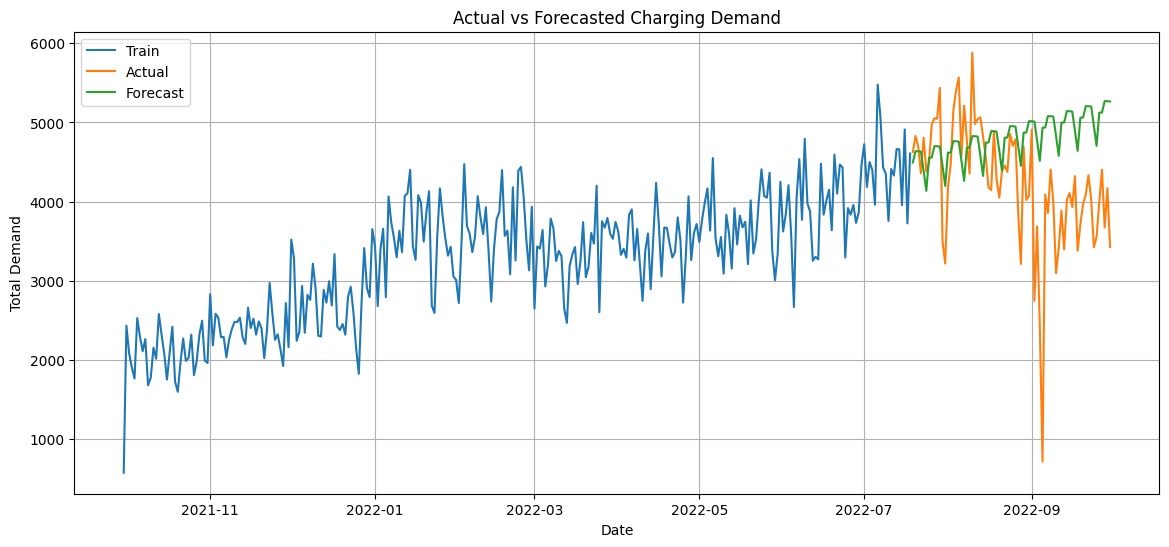

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(
    train['date'],
    train['total_demand'],
    label='Train'
)

plt.plot(
    test['date'],
    test['total_demand'],
    label='Actual'
)

plt.plot(
    test['date'],
    forecast,
    label='Forecast'
)

plt.title('Actual vs Forecasted Charging Demand')
plt.xlabel('Date')
plt.ylabel('Total Demand')

plt.legend()
plt.grid()

plt.savefig(
    "images/es_weekly_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    test['total_demand'],
    forecast
)

rmse = np.sqrt(
    mean_squared_error(
        test['total_demand'],
        forecast
    )
)

print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE : 790.79
RMSE: 1028.69


# Step 13 — 7-day Moving Average forecast model

### What this forecasting model does
For each day in the test period, the model predicts demand using the **average of the most recent 7 actual demand values**.

### Why `window = 7`?
The data is daily, so a window of 7 represents approximately one week of recent demand.

For every test day:
1. Take the latest 7 demand values from `history`.
2. Calculate their average.
3. Store that value as the next-day prediction.
4. After the actual test value becomes available, add it to `history`.
5. Repeat for the following day.

### Saved evaluation result
- **MAE = 495.04**
- **RMSE = 686.51**

These are the lowest recorded errors in the current notebook.

### Graph explanation
The forecast line follows the recent local demand level because each new prediction is based on the latest seven actual observations. It is smoother than the actual test series and will not reproduce every sudden spike or drop.


7-Day Moving Average
MAE : 495.04
RMSE: 686.51


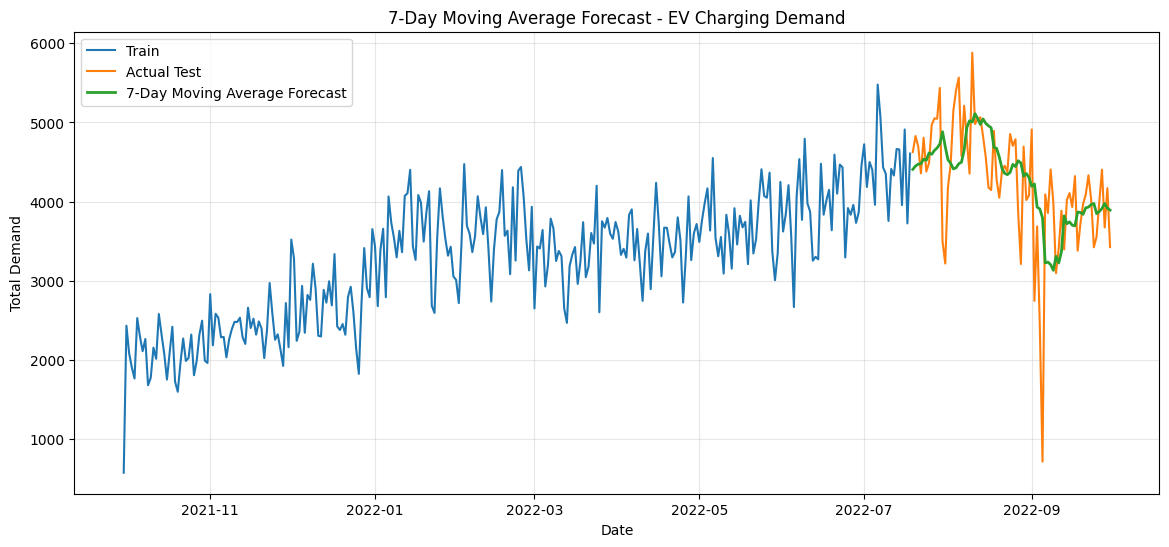

In [24]:
# 7-day Moving Average forecasting model
window = 7

# Use only the numeric demand values from training data
history = list(train['total_demand'])

# Store predictions
predictions = []

# Walk-forward forecasting
for t in range(len(test)):

    # Take the latest 7 actual demand values
    recent_values = history[-window:]

    # Calculate their average
    forecast = np.mean(recent_values)

    # Store the forecast
    predictions.append(forecast)

    # Add the actual test demand to history
    # so it can be used for the next day's prediction
    history.append(test['total_demand'].iloc[t])


# Convert predictions to numpy array
predictions = np.array(predictions)


# ---------------------------------------------------------
# Model Evaluation
# ---------------------------------------------------------

mae_ma7 = mean_absolute_error(
    test['total_demand'],
    predictions
)

rmse_ma7 = np.sqrt(
    mean_squared_error(
        test['total_demand'],
        predictions
    )
)

print("7-Day Moving Average")
print("MAE :", round(mae_ma7, 2))
print("RMSE:", round(rmse_ma7, 2))


# ---------------------------------------------------------
# Actual vs Forecast Graph
# ---------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    train['date'],
    train['total_demand'],
    label='Train'
)

plt.plot(
    test['date'],
    test['total_demand'],
    label='Actual Test'
)

plt.plot(
    test['date'],
    predictions,
    label='7-Day Moving Average Forecast',
    linewidth=2
)

plt.title('7-Day Moving Average Forecast - EV Charging Demand')
plt.xlabel('Date')
plt.ylabel('Total Demand')

plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "images/moving_average_7day_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 14 — Identify periods of increasing/decreasing demand

`pct_change() * 100` calculates the day-to-day percentage change:

**(today − yesterday) / yesterday × 100**

### Why use percentage change?
It helps identify unusually strong increases or decreases in daily demand.

### Observations
- Largest positive change: **+468.53% on 06-Sep-2022**
- Largest negative change: **−70.32% on 05-Sep-2022**
- Demand on 05-Sep-2022 was only **719.62**, so the next day's percentage rebound becomes very large.

### Interpretation
Percentage change can become extremely large when the previous day's value is unusually small. Therefore, extreme percentages should be interpreted together with the original demand values.


In [25]:
daily_demand['pct_change'] = (
    daily_demand['total_demand']
    .pct_change() * 100
)

In [26]:
daily_demand.loc[
    daily_demand['pct_change'].idxmax()
]

date            2022-09-06 00:00:00
total_demand                4091.27
MA_7                    3237.205714
pct_change               468.532003
Name: 341, dtype: object

In [27]:
daily_demand.loc[
    daily_demand['pct_change'].idxmin()
]

date            2022-09-05 00:00:00
total_demand                 719.62
MA_7                    3227.162857
pct_change               -70.317359
Name: 340, dtype: object

## Step 15 — First differencing to make the series stationary

### What is first differencing?
First differencing calculates:

**Today's demand − Yesterday's demand**

Instead of modeling the original level directly, it analyzes how much demand changed from one day to the next.

Examples:
- 01-Oct-2021: 2434.41 − 579.19 = **+1855.22**
- 02-Oct-2021: 2087.74 − 2434.41 = **−346.67**

The first difference is `NaN` because 30-Sep-2021 has no previous day.

### Why do we do this?
The original ADF test showed non-stationarity. Differencing is a common way to remove changing level/trend behavior and make the series more stationary.

### ADF result after differencing
- ADF statistic: **-8.1081**
- p-value: **1.247 × 10⁻¹²**

Because the p-value is far below 0.05, the differenced series is treated as **stationary**.

Since first differencing produced a stationary series, d=1 was selected for the ARIMA model.

### Differenced graph explanation
The differenced series fluctuates around a more stable central level, roughly around zero, rather than preserving the original long-term upward level.


In [28]:
# Differencing
daily_demand['demand_diff'] = (
    daily_demand['total_demand']
    .diff()
)

print(daily_demand[['total_demand', 'demand_diff']].head(10))

   total_demand  demand_diff
0        579.19          NaN
1       2434.41      1855.22
2       2087.74      -346.67
3       1907.85      -179.89
4       1768.66      -139.19
5       2530.75       762.09
6       2300.17      -230.58
7       2112.87      -187.30
8       2266.39       153.52
9       1683.26      -583.13


In [29]:
from statsmodels.tsa.stattools import adfuller

# Remove first NaN value
differenced_data = daily_demand['demand_diff'].dropna()

# ADF test
result = adfuller(differenced_data)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] <= 0.05:
    print("Differenced series is STATIONARY")
else:
    print("Differenced series is NON-STATIONARY")

ADF Statistic: -8.10809603435371
p-value: 1.247007142671032e-12
Differenced series is STATIONARY


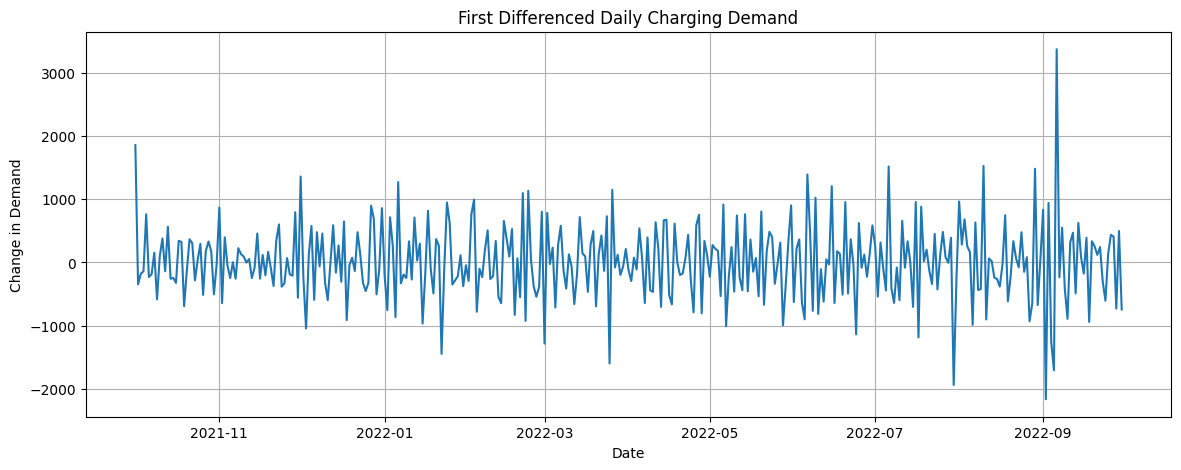

In [30]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_demand.loc[differenced_data.index, 'date'],
    differenced_data
)

plt.title('First Differenced Daily Charging Demand')
plt.xlabel('Date')
plt.ylabel('Change in Demand')

plt.grid()
plt.show()


## Step 16 — Reconfirm the train-test split before ARIMA

The same chronological 80/20 train-test split before fitting ARIMA.

The code prints `train.index` and `test.index`, so the displayed values `0 to 291` and `292 to 365` are **row index positions**, not calendar dates.

The actual date ranges were already confirmed earlier:
- Train: 30-Sep-2021 to 18-Jul-2022
- Test: 19-Jul-2022 to 30-Sep-2022

No random shuffling is used.

In [31]:
# 80% train, 20% test
split_point = int(len(daily_demand) * 0.80)

train = daily_demand.iloc[:split_point]
test = daily_demand.iloc[split_point:]

print("Train size:", len(train))
print("Test size :", len(test))

print("\nTrain period:")
print(train.index.min(), "to", train.index.max())

print("\nTest period:")
print(test.index.min(), "to", test.index.max())

Train size: 292
Test size : 74

Train period:
0 to 291

Test period:
292 to 365


## Step 17 — ARIMA(1,1,1)

### What is ARIMA?
**ARIMA = AutoRegressive Integrated Moving Average**

It is a classical time-series forecasting model that combines:
- past values,
- differencing,
- past forecast errors.

### Meaning of `ARIMA(p,d,q)`
For `ARIMA(1,1,1)`:
- **p = 1** → uses one autoregressive lag term.
- **d = 1** → applies one differencing step.
- **q = 1** → uses one moving-average error term.

### Why `d=1` makes sense here
The original series was non-stationary, but first differencing produced a stationary series. Therefore, one differencing step is a reasonable starting choice.

### Saved ARIMA test result
- **MAE = 568.27**
- **RMSE = 788.70**

### Metric interpretation
ARIMA performs better than both Exponential Smoothing versions and the Naive Baseline in the saved results.

The 7-day Moving Average has lower recorded MAE and RMSE (**495.04 / 686.51**), but it is evaluated with one-step-ahead walk-forward updates, while ARIMA forecasts the complete test period at once. That difference in evaluation setup should be mentioned when comparing them.

### Graph explanation
The ARIMA forecast becomes relatively flat around the learned demand level. It does not reproduce every daily spike or sudden drop.


In [32]:
from statsmodels.tsa.arima.model import ARIMA

# ARIMA model
arima_model = ARIMA(
    train['total_demand'],
    order=(1, 1, 1)
)

arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:           total_demand   No. Observations:                  292
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -2186.033
Date:                Tue, 03 Nov 2026   AIC                           4378.066
Time:                        20:59:31   BIC                           4389.086
Sample:                             0   HQIC                          4382.481
                                - 292                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1313      0.068      1.926      0.054      -0.002       0.265
ma.L1         -0.8651      0.034    -25.773      0.000      -0.931      -0.799
sigma2      1.942e+05   1.49e+04     13.020      0.0

In [33]:
arima_forecast = arima_fit.forecast(
    steps=len(test)
)
print(arima_forecast.head())

292    4410.181713
293    4384.311956
294    4380.914057
295    4380.467756
296    4380.409135
Name: predicted_mean, dtype: float64


In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

arima_mae = mean_absolute_error(
    test['total_demand'],
    arima_forecast
)

arima_rmse = np.sqrt(
    mean_squared_error(
        test['total_demand'],
        arima_forecast
    )
)

print("ARIMA MAE :", round(arima_mae, 2))
print("ARIMA RMSE:", round(arima_rmse, 2))

ARIMA MAE : 568.27
ARIMA RMSE: 788.7


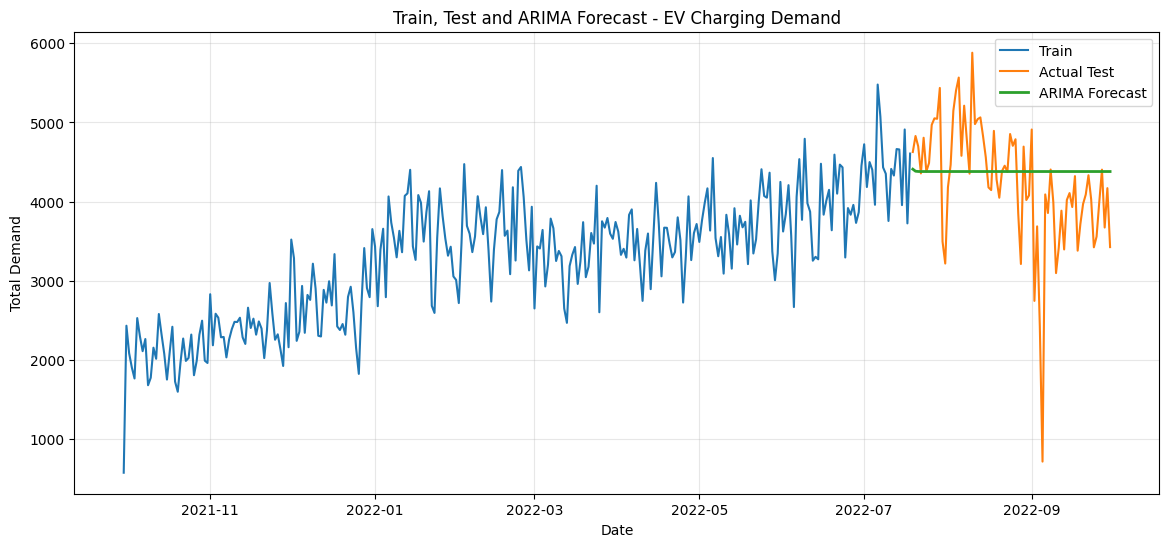

In [35]:
plt.figure(figsize=(14, 6))

# Training data
plt.plot(
    train['date'],
    train['total_demand'],
    label='Train'
)

# Actual test data
plt.plot(
    test['date'],
    test['total_demand'],
    label='Actual Test'
)

# ARIMA forecast
plt.plot(
    test['date'],
    arima_forecast,
    label='ARIMA Forecast',
    linewidth=2
)

plt.title('Train, Test and ARIMA Forecast - EV Charging Demand')
plt.xlabel('Date')
plt.ylabel('Total Demand')

plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "images/arima_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 18 — Naive Baseline comparison

### What is a baseline?
A baseline is a very simple prediction method used as a reference. A forecasting model should ideally provide useful improvement over this simple benchmark.

### Baseline used here
The Naive Baseline predicts the **last observed training demand** for every day in the test period.

### Results

**Naive Baseline**
- MAE = **629.47**
- RMSE = **859.25**

**ARIMA(1,1,1)**
- MAE = **568.27**
- RMSE = **788.70**

**7-Day Moving Average**
- MAE = **495.04**
- RMSE = **686.51**

### Interpretation
ARIMA has lower MAE and RMSE than the Naive Baseline, so ARIMA improves on that simple fixed benchmark.

The 7-day Moving Average has the lowest recorded errors in the current notebook. However, it uses one-step-ahead walk-forward updates with actual test observations, whereas the ARIMA and Naive forecasts shown here are generated without those day-by-day updates.

In [36]:
# Predict the last training demand for every day in the test period
last_train_value = train['total_demand'].iloc[-1]
baseline_forecast = np.repeat(last_train_value, len(test))

baseline_mae = mean_absolute_error(
    test['total_demand'],
    baseline_forecast
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        test['total_demand'],
        baseline_forecast
    )
)

print("Naive Baseline MAE :", round(baseline_mae, 2))
print("Naive Baseline RMSE:", round(baseline_rmse, 2))

print("\nARIMA MAE :", round(arima_mae, 2))
print("ARIMA RMSE:", round(arima_rmse, 2))


Naive Baseline MAE : 629.47
Naive Baseline RMSE: 859.25

ARIMA MAE : 568.27
ARIMA RMSE: 788.7


# Step 19 — Evaluation-metric comparison plot

### MAE
**Mean Absolute Error** measures the average absolute forecast error in the same units as demand.

### RMSE
**Root Mean Squared Error** also measures error in demand units, but gives a larger penalty to bigger mistakes.

### How to read the chart
For both MAE and RMSE:

> **Lower bar = lower forecast error**

The chart now compares the remaining saved evaluation results for:
- Exponential Smoothing — trend only
- Exponential Smoothing — trend + weekly seasonality
- 7-Day Moving Average
- Naive Baseline
- ARIMA(1,1,1)

The removed **Damped + Weekly Seasonality** and **SARIMA** models are no longer included.

### Main result
The 7-day Moving Average has the lowest recorded MAE (**495.04**) and RMSE (**686.51**) in the current notebook.

### Important fairness note
The Moving Average is evaluated using one-step-ahead walk-forward updates with actual test observations. ARIMA is evaluated as a fixed multi-step forecast for the full test period. Therefore, the bars show the recorded errors correctly, but the forecasting protocols are not identical.


                           Model     MAE     RMSE
0                  ES Trend Only  784.00  1028.75
1  ES Trend + Weekly Seasonality  790.79  1028.69
2           7-Day Moving Average  495.04   686.51
3                 Naive Baseline  629.47   859.25
4                   ARIMA(1,1,1)  568.27   788.70


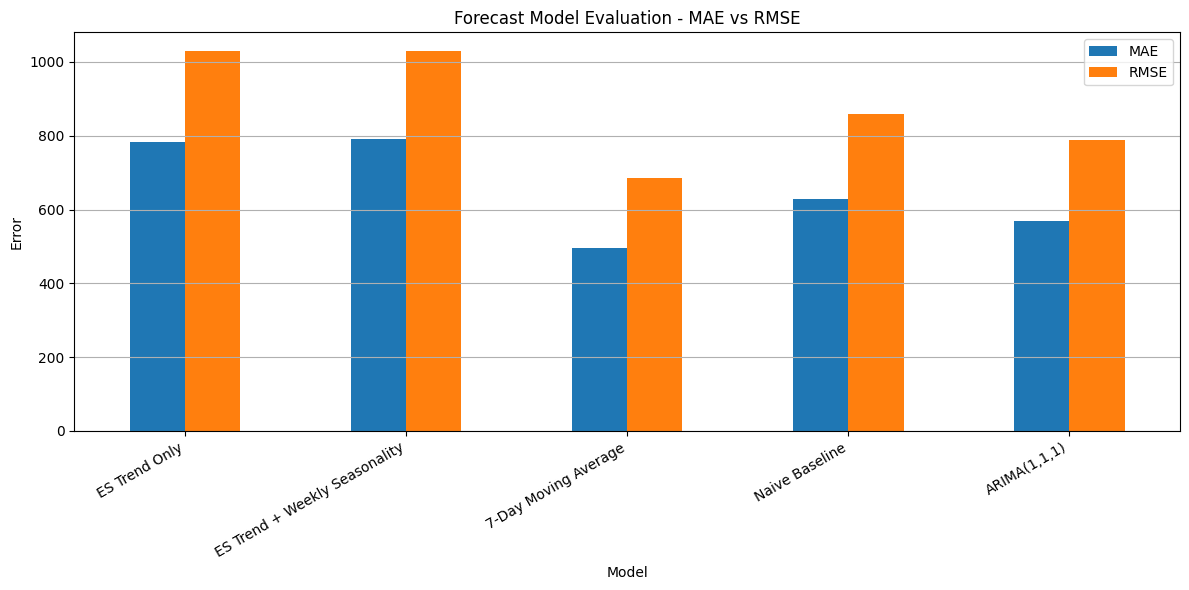

In [37]:
# Model evaluation metrics plot
# Values below are the saved results produced in this notebook

model_metrics = pd.DataFrame({
    'Model': [
        'ES Trend Only',
        'ES Trend + Weekly Seasonality',
        '7-Day Moving Average',
        'Naive Baseline',
        'ARIMA(1,1,1)'
    ],
    'MAE': [
        784.00,
        790.79,
        495.04,
        629.47,
        568.27
    ],
    'RMSE': [
        1028.75,
        1028.69,
        686.51,
        859.25,
        788.70
    ]
})

print(model_metrics)

ax = model_metrics.set_index('Model')[['MAE', 'RMSE']].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Forecast Model Evaluation - MAE vs RMSE')
plt.xlabel('Model')
plt.ylabel('Error')
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


# Step 20 — Final model comparison

| Model | MAE | RMSE | Simple interpretation |
|---|---:|---:|---|
| Exponential Smoothing — Trend Only | 784.00 | 1028.75 | Captures broad trend, but test errors are relatively high. |
| Exponential Smoothing — Trend + Weekly Seasonality | 790.79 | 1028.69 | Adds a weekly cycle, but accuracy did not improve. |
| **7-Day Moving Average** | **495.04** | **686.51** | **Lowest recorded MAE and RMSE in the current notebook; evaluated using walk-forward updates.** |
| Naive Baseline | 629.47 | 859.25 | Simple benchmark using the last training value. |
| ARIMA(1,1,1) | 568.27 | 788.70 | Better than the baseline and both Exponential Smoothing versions. |

## Final interpretation
The 7-day Moving Average achieved the lowest recorded MAE (495.04) and RMSE (686.51) among all evaluated forecasting methods. Under the current evaluation setup, it produced the best forecasting performance.

Under the current evaluation setup, the 7-day Moving Average achieved the lowest MAE and RMSE and therefore produced the best recorded forecasting performance in this notebook.